# ZEDYB — Zero-Shot Detection of AI-Generated Images (SReC + ZED surprise score)

Pipeline:

1. **Category CNN.** A ResNet-18, validated with 5-fold CV, routes each image to one of three streams: `photo`, `art` or `text`.
2. **Three SReC streams.** For each category, the SReC lossless coder (Cao et al., 2020, `caoscott/SReC`) is fine-tuned on
   **real images only**, with 5-fold CV. From SReC's per-pixel distributions we compute the ZED surprise statistics of
   Cozzolino et al. (ECCV 2024, arXiv:2409.15875), §3:
   * actual coding cost `NLL = −log p(x_true)` and expected coding cost `H = −Σ_v p(v) log p(v)`, averaged per level `l ∈ {0,1,2}`
     (level 0 is full resolution and level 3 is the 8×-down-sampled prompt sent in clear, which is not scored);
   * `D(l) = NLL(l) − H(l)` and `Δ01 = D(0) − D(1)`. The decision statistics are `D(0)`, `|D(0)|`, `Δ01` and `|Δ01|`, and `|Δ01|` scores best in the paper.
     Fakes are expected to have a **positive** gap.
3. **Zero-shot threshold.** The threshold is the 95th percentile of the out-of-fold scores of *real* training images. No AI image
   is seen before the single evaluation on the held-out test sets (40 AI + 10 real per category).

> **Run this on a GPU.** A Colab T4 is fine; expect on the order of an hour (estimate; the smoke test was timed on CPU only). Set `SMOKE = True` (or env `ZEDYB_SMOKE=1`) for a
> 5-minute CPU run that exercises every cell on tiny data.

<details><summary><b>What changed compared with the previous version</b> (click)</summary>

**Bugs fixed**
* **AniPrO passwords.** `PASSWORDS.csv` has a header (`created_at,class,part,archive,password,…`) and a UTF-8 BOM. The old code used
  column 0 as the key and column 1 as the password, so the lookup always failed. It now uses `csv.DictReader` on `archive → password`.
* **AniPrO reals were mostly JPEG** (about 72 % of `real/`), while every AI image is PNG. A lossless-coding detector would partly detect *the
  file format*. Only PNG reals are used now.
* **TextRich `CommercialPosters`** had the same confound: its reals are JPEG and its fakes PNG. The default is now **`AcademicPosters`**, the only
  TextRich category where both reals and fakes are PNG. (`UIScreenshots` *does* have fakes now, but its reals are JPEG.)
* **TextRich / silatus downloads** used `snapshot_download` with folder patterns, which pulled the whole folder (about 2,000 files).
  Now only the sampled files are downloaded.
* **RGBA images** (screenshots, posters) were converted with `.convert("RGB")`, which leaves arbitrary colours under transparent
  pixels. They are now composited onto white.

**Method / evaluation improvements**
* **Photo fakes** now default to **Synthbuster** (7 generators, lossless PNG, ≥ 512 px; Firefly is excluded because its ".png" files are JPEG). CIFAKE is 32×32 and could be
  separated by image size alone; it is still available via `PHOTO_FAKE_SOURCE = "cifake"`.
* All loaders enforce `min side ≥ CROP`, so **every image is scored on an identical 512×512 crop** (crops are multiples of 8, so the
  2×2 groups align at every level).
* **Range-request downloads.** Only the files needed are fetched from the DIV2K zip (≈3.5 GB), the Synthbuster zip (12 GB) and the
  AniPrO zips (1 GB each).
* **Danbooru.** The `id ≤ 5,020,995` filter is applied server-side, and posts tagged `jpeg_artifacts`/`ai-generated` are skipped.
* **Format audit.** A manifest records the source format of every image, and a JPEG-blockiness check flags a real-vs-fake
  format mismatch before any result is computed.
* **Self-check.** ZED's per-level NLL is verified against SReC's own bit count.
* **Faster entropy.** Computing the CDF at 257 bin edges gives the same result to about 1e-6 and runs about 4× faster.
* **Extra statistics `cD0`, `cΔ01`.** These are the distance to the median of the stream's *real* OOF scores. They are still zero-shot and correct
  for the encoder's bias on a domain (real images rarely sit at exactly D = 0).
* **Evaluation.** The evaluation now adds bootstrap 95 % CIs on the AUC, ROC curves, TPR per generator, an AUC against the 200 OOF reals (with only 10
  test reals the test FPR moves in steps of 10 %), and a **pretrained-SReC baseline** (no fine-tuning) as an ablation.
* **Fine-tuning.** Fine-tuning now uses warm-up, cosine decay, lr = 3e-6 and **checkpoint selection on held-out real images**. Without warm-up, Adam's first steps made the
  pretrained coder *worse* on unseen reals. The final model's step count is the median best step from CV, so everything is chosen on reals only.
* **Resumability.** Fold scores and stream checkpoints are cached, so a Colab disconnect does not restart the run.
</details>

## 0. Setup

In [1]:
import os, sys, io, csv, json, math, time, random, hashlib, shutil, zipfile, subprocess, urllib.request, importlib
from pathlib import Path

# ---- dependencies (installed only if missing) ----
_REQ = {"remotezip": "remotezip", "pyzipper": "pyzipper", "huggingface_hub": "huggingface_hub",
        "sklearn": "scikit-learn", "tqdm": "tqdm", "pandas": "pandas", "matplotlib": "matplotlib",
        "requests": "requests", "torchvision": "torchvision"}
_missing = [pip for mod, pip in _REQ.items() if importlib.util.find_spec(mod) is None]
if _missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_missing], check=True)

import numpy as np, pandas as pd
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True
Image.MAX_IMAGE_PIXELS = None           # posters / screenshots can be > 89 Mpx
from tqdm.auto import tqdm
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, roc_curve

# ---- configuration ----
SMOKE = os.environ.get("ZEDYB_SMOKE", "0") == "1"   # or set True by hand: tiny data, CPU-friendly
CATS = ["photo", "art", "text"]
N_TRAIN_PER_CAT, N_TEST_FAKE, N_TEST_REAL = 200, 40, 10
K_FOLDS = 5
CROP = 512               # square centre crop for scoring (multiple of 8). CROP, never RESIZE.
STEPS, LR, BATCH, TRAIN_CROP = 600, 3e-6, 8, 128      # SReC fine-tuning per fold (lr: see §4)
WARMUP_FRAC, EVAL_EVERY, INNER_VAL_FRAC = 0.1, 100, 0.1
JPEG_AUG = 0.0           # 0.5 mimics ZED's "COCO*" encoder (half the crops JPEG q80-100)
CAT_EPOCHS = 5
TARGET_FPR = 0.05
PHOTO_FAKE_SOURCE = "synthbuster"       # "synthbuster" (recommended) | "cifake" (32x32, see §1b)
TEXTRICH_CATS = ["AcademicPosters"]     # the only TextRich category with PNG reals AND PNG fakes
RUN_PRETRAINED_BASELINE = True          # ablation: original OpenImages SReC, no fine-tuning
N_BOOT = 2000
RECOMPUTE = False        # True -> ignore cached fold scores / checkpoints
if SMOKE:
    N_TRAIN_PER_CAT, N_TEST_FAKE, N_TEST_REAL, K_FOLDS = 10, 4, 2, 2
    CROP, STEPS, CAT_EPOCHS, N_BOOT, EVAL_EVERY = 128, 4, 1, 200, 2
MIN_SIDE = CROP          # sampling skips images smaller than the crop -> every image is scored at the same size

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
NUM_WORKERS = 2 if DEVICE == "cuda" else 0
print("device:", DEVICE, "| smoke:", SMOKE)

ROOT = Path(".").resolve()
SREC_DIR = ROOT / "SReC"
DATA = ROOT / ("data_smoke" if SMOKE else "data")
OUT = ROOT / ("results_smoke" if SMOKE else "results")
OUT.mkdir(exist_ok=True)
SPLITS = ["train/photo", "train/art", "train/text"] + [f"test/{c}/{s}" for c in CATS for s in ("real", "fake")]
for p in SPLITS: (DATA / p).mkdir(parents=True, exist_ok=True)

# ---- SReC ----
if not (SREC_DIR / "src" / "network.py").exists():
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/caoscott/SReC.git", str(SREC_DIR)], check=True)
sys.path.insert(0, str(SREC_DIR))
from src import configs as srec_configs
from src import network as srec_network
from src import data as srec_data
from src import util as srec_util
from src.l3c import logistic_mixture as lm
assert (SREC_DIR / "models" / "openimages.pth").exists()

device: cpu | smoke: False


Cloning into '/Users/yanbingzhao/Documents/MGSC 673/individual project/SReC'...


## 1. Data

Each loader only fills a folder, so you can swap any source by dropping PNGs into `data/train/<cat>/` or
`data/test/<cat>/{real,fake}/`. Every saved image is logged in `data/manifest.csv` with its **source format** and size.

| | Photographs | Digital art | Text-heavy |
|---|---|---|---|
| train (200 real) | DIV2K **train** HR (PNG) | Danbooru, post id ≤ 5,020,995 (pre-2022), PNG | silatus/1k_Website_Screenshots (PNG) |
| test real (10) | DIV2K **validation** HR (disjoint) | AniPrO `real/`, **PNG only** | TextRich `AcademicPosters/0_real` (PNG) |
| test fake (40) | **Synthbuster**, 7 generators (PNG) | AniPrO `text2image/` (SD / SDXL / FLUX.1, PNG) | TextRich `AcademicPosters/1_fake` (GPT-Image-2, PNG) |

In [2]:
def list_images(folder, exts=(".png", ".jpg", ".jpeg", ".webp")):
    return sorted(p for p in Path(folder).rglob("*") if p.suffix.lower() in exts)

def n_missing(folder, n):
    return max(0, n - len(list_images(folder)))

def to_rgb(img):
    """RGB conversion that composites transparency onto white (plain .convert('RGB') keeps junk colours under alpha=0)."""
    if img.mode in ("RGBA", "LA") or (img.mode == "P" and "transparency" in img.info):
        img = img.convert("RGBA")
        bg = Image.new("RGB", img.size, (255, 255, 255)); bg.paste(img, mask=img.split()[-1])
        return bg
    return img.convert("RGB")

MANIFEST = DATA / "manifest.csv"
MANIFEST_COLS = ["path", "split", "cat", "label", "source", "generator", "src_format", "src_w", "src_h"]

def save_image(src, dst, split, cat, label, source, generator="", min_side=None, require_format="PNG"):
    """src: path or raw bytes. Saves RGB PNG (storage format never leaks into the score) and logs provenance.
    Returns False (and saves nothing) if the image is smaller than min_side or its *content* is not require_format
    (file extensions lie: e.g. Synthbuster's Firefly ".png" files are JPEG)."""
    im = Image.open(io.BytesIO(src) if isinstance(src, (bytes, bytearray)) else src)
    fmt, (w, h) = im.format, im.size
    if (min_side and min(w, h) < min_side) or (require_format and fmt != require_format):
        return False
    to_rgb(im).save(dst, "PNG")
    row = dict(path=str(Path(dst).relative_to(DATA)), split=split, cat=cat, label=label, source=source,
               generator=generator, src_format=fmt, src_w=w, src_h=h)
    new = not MANIFEST.exists()
    with open(MANIFEST, "a", newline="") as f:
        wr = csv.DictWriter(f, MANIFEST_COLS)
        if new: wr.writeheader()
        wr.writerow(row)
    return True

def load_manifest():
    m = pd.read_csv(MANIFEST, keep_default_na=False) if MANIFEST.exists() else pd.DataFrame(columns=MANIFEST_COLS)
    m = m.drop_duplicates("path", keep="last")
    return m[m.path.map(lambda p: (DATA / p).exists())]

class open_remote_zip:
    """Read members of a remote zip with HTTP range requests (no full download). Falls back to downloading."""
    def __init__(self, url, cache=None): self.url, self.cache = url, cache
    def __enter__(self):
        try:
            from remotezip import RemoteZip
            self.z = RemoteZip(self.url); return self.z
        except Exception as e:
            print("range requests failed (", e, ") -> downloading the whole archive")
            dst = self.cache or DATA / Path(self.url.split("?")[0]).name
            if not Path(dst).exists(): urllib.request.urlretrieve(self.url, dst)
            self.z = zipfile.ZipFile(dst); return self.z
    def __exit__(self, *a): self.z.close()

def quotas(n, groups):
    """Split n as evenly as possible across groups."""
    return {g: n // len(groups) + (i < n % len(groups)) for i, g in enumerate(groups)}

### 1a. Photographs: DIV2K (200 train HR for training, 10 validation HR for testing). Only these files are downloaded.

In [3]:
DIV2K = {"train": "https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_HR.zip",   # 800 PNG, ~3.5 GB zip
         "valid": "https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_valid_HR.zip"}   # 100 PNG

def div2k_fetch(which, n, dst, split, label):
    if n_missing(dst, n) == 0: return
    with open_remote_zip(DIV2K[which]) as z:
        names = sorted(m for m in z.namelist() if m.endswith(".png"))
        random.Random(SEED).shuffle(names)
        for name in tqdm(names, desc=f"DIV2K {which}"):
            if n_missing(dst, n) == 0: break
            out = Path(dst) / f"div2k_{Path(name).stem}.png"
            if not out.exists():
                save_image(z.read(name), out, split, "photo", label, f"DIV2K_{which}", min_side=MIN_SIDE)
    print(dst, len(list_images(dst)))

div2k_fetch("train", N_TRAIN_PER_CAT, DATA / "train/photo", "train", "real")
div2k_fetch("valid", N_TEST_REAL, DATA / "test/photo/real", "test", "real")

DIV2K train:   0%|          | 0/800 [00:00<?, ?it/s]

/Users/yanbingzhao/Documents/MGSC 673/individual project/data/train/photo 200


DIV2K valid:   0%|          | 0/100 [00:00<?, ?it/s]

/Users/yanbingzhao/Documents/MGSC 673/individual project/data/test/photo/real 10


### 1b. Photographs: AI test images

**Default: Synthbuster** (Bammey 2023, Zenodo 10066460). It contains 1,000 lossless PNGs per generator, made from RAISE-1k
prompts. We take about 6 images from each of 7 generators (DALL·E 2/3, Midjourney v5, SD 1.3/1.4/2, SDXL). Two are excluded:
**GLIDE**, because its images are 256×256 (below the crop), and **Firefly**, because its `.png` files actually contain JPEG data.
`save_image` checks the decoded format, not the file extension.

**Alternative: CIFAKE** (`PHOTO_FAKE_SOURCE = "cifake"`). ⚠️ CIFAKE images are **32×32**. SReC's 3 down-sampling levels reduce
them to a 4×4 prompt, and the classes become separable by **size alone**, so photo-stream results would be meaningless. The size filter is
disabled for CIFAKE, so the mismatch is visible in the audit (§1g).

In [4]:
SYNTHBUSTER_URL = "https://zenodo.org/records/10066460/files/synthbuster.zip?download=1"   # 12 GB, read by range requests
SB_GENERATORS = ["dalle2", "dalle3", "midjourney-v5", "stable-diffusion-1-3",      # glide: 256 px; firefly: JPEG content
                 "stable-diffusion-1-4", "stable-diffusion-2", "stable-diffusion-xl"]
dst = DATA / "test/photo/fake"

if n_missing(dst, N_TEST_FAKE) and PHOTO_FAKE_SOURCE == "synthbuster":
    with open_remote_zip(SYNTHBUSTER_URL) as z:
        names = [m for m in z.namelist() if m.lower().endswith(".png")]
        have = load_manifest().query("split=='test' and cat=='photo' and label=='fake'").generator.value_counts()
        for gen, q in quotas(N_TEST_FAKE, SB_GENERATORS).items():
            cand = sorted(m for m in names if m.split("/")[-2] == gen)
            random.Random(f"{SEED}-{gen}").shuffle(cand)     # per-generator order -> different prompts per generator
            got = int(have.get(gen, 0))
            for m in cand:
                if got >= q: break
                out = dst / f"sb_{gen}_{Path(m).stem}.png"
                if out.exists(): continue
                got += save_image(z.read(m), out, "test", "photo", "fake", "Synthbuster", gen, min_side=MIN_SIDE)
            print(f"  {gen}: {got}")

elif n_missing(dst, N_TEST_FAKE) and PHOTO_FAKE_SOURCE == "cifake":
    import kagglehub   # needs ~/.kaggle/kaggle.json or KAGGLE_USERNAME / KAGGLE_KEY
    path = Path(kagglehub.dataset_download("birdy654/cifake-real-and-ai-generated-synthetic-images"))
    fakes = list_images(path / "test" / "FAKE"); random.Random(SEED).shuffle(fakes)
    for p in fakes[:N_TEST_FAKE]:
        save_image(p, dst / f"cifake_{p.stem}.png", "test", "photo", "fake", "CIFAKE", "cifake", require_format=None)
print(dst, len(list_images(dst)))

  dalle2: 6
  dalle3: 6
  midjourney-v5: 6
  stable-diffusion-1-3: 6
  stable-diffusion-1-4: 6
  stable-diffusion-2: 5
  stable-diffusion-xl: 5
/Users/yanbingzhao/Documents/MGSC 673/individual project/data/test/photo/fake 40


### 1c. Digital art, training: Danbooru, uploaded before 2022 (post id ≤ 5,020,995, the last Danbooru2021 id)

The cell queries the Danbooru API with `id:..5020995 filetype:png rating:g` (filtered server-side). It skips posts tagged
`jpeg_artifacts`, `ai-generated`, `photo_(medium)`, `3d` or `comic`, and posts smaller than the crop. The anonymous API is rate-limited, so the cell
takes about 5 minutes and is safe to re-run (it resumes).
**Alternative:** put about 200 PNGs from [DanbooruDownloader](https://github.com/KichangKim/DanbooruDownloader) (id ≤ 5,020,995) into `data/train/art/`.

In [5]:
DANBOORU_LAST_2021_ID = 5020995
DANBOORU_BAD_TAGS = {"jpeg_artifacts", "ai-generated", "ai-assisted", "photo_(medium)", "3d", "comic"}

def danbooru_fetch(n, out_dir, max_rounds=60):
    import requests
    S = requests.Session(); S.headers["User-Agent"] = "zedyb-course-project/1.0 (academic research)"
    tags = f"id:..{DANBOORU_LAST_2021_ID} filetype:png rating:g"
    rounds, pbar = 0, tqdm(total=n, initial=n - n_missing(out_dir, n), desc="Danbooru")
    while n_missing(out_dir, n) and rounds < max_rounds:
        rounds += 1
        try:
            r = S.get("https://danbooru.donmai.us/posts.json",
                      params={"tags": tags, "limit": 100, "random": "true"}, timeout=60)
        except Exception as e:
            print("request failed:", e); time.sleep(10); continue
        if r.status_code != 200:
            print("API status", r.status_code, "- backing off"); time.sleep(15); continue
        for p in r.json():
            if not n_missing(out_dir, n): break
            if (p.get("id", 10**9) > DANBOORU_LAST_2021_ID or p.get("file_ext") != "png" or not p.get("file_url")
                    or min(p.get("image_width", 0), p.get("image_height", 0)) < MIN_SIDE
                    or p.get("file_size", 0) > 30e6
                    or DANBOORU_BAD_TAGS & set(p.get("tag_string", "").split())):
                continue
            dst = Path(out_dir) / f"danbooru_{p['id']}.png"
            if dst.exists(): continue
            try:
                b = S.get(p["file_url"], timeout=120).content
                if save_image(b, dst, "train", "art", "real", "Danbooru<=2021", min_side=MIN_SIDE): pbar.update(1)
            except Exception as e:
                print("fail", p["id"], e)
            time.sleep(0.5)
    pbar.close(); print(out_dir, len(list_images(out_dir)))

if n_missing(DATA / "train/art", N_TRAIN_PER_CAT):
    danbooru_fetch(N_TRAIN_PER_CAT, DATA / "train/art")

Danbooru:   0%|          | 0/200 [00:00<?, ?it/s]

/Users/yanbingzhao/Documents/MGSC 673/individual project/data/train/art 200


### 1d. Digital art, test: AniPrO (`real/` gives 10 PNG reals, `text2image/` gives 40 fakes balanced across SD, SDXL and FLUX.1)

The zips are AES-encrypted (7-Zip), and their passwords ship in `PASSWORDS.csv`. They are read remotely, so roughly 50 files are fetched instead of 2 GB.
Real and fake ids are kept disjoint, because the same id means the same source illustration.

In [6]:
ANIPRO = "YAN-LIU05/AniPro"

def anipro_passwords():
    from huggingface_hub import hf_hub_download
    p = hf_hub_download(ANIPRO, "anime_dataset_zip/PASSWORDS.csv", repo_type="dataset")
    with open(p, newline="", encoding="utf-8-sig") as f:          # header row + BOM
        return {r["archive"]: r["password"] for r in csv.DictReader(f)}

class anipro_zip:
    def __init__(self, archive): self.archive = archive
    def __enter__(self):
        import pyzipper
        from huggingface_hub import HfFileSystem
        self.f = HfFileSystem().open(f"datasets/{ANIPRO}/anime_dataset_zip/{self.archive}", "rb", block_size=2**20)
        self.z = pyzipper.AESZipFile(self.f); self.z.setpassword(ANIPRO_PW[self.archive].encode())
        return self.z
    def __exit__(self, *a): self.z.close(); self.f.close()

def anipro_gen(name):     # text2image/<id>/0010_text2image_<id>_<GEN>_text2image_<id>.png
    return Path(name.replace("\\", "/")).stem.split("_")[3]

def anipro_id(name):
    p = Path(name.replace("\\", "/"))
    return p.stem if p.parent.name == "real" else p.parent.name

fake_dir, real_dir = DATA / "test/art/fake", DATA / "test/art/real"
if n_missing(fake_dir, N_TEST_FAKE) or n_missing(real_dir, N_TEST_REAL):
    ANIPRO_PW = anipro_passwords()
    with anipro_zip("text2image_part001.zip") as z:
        names = [m for m in z.namelist() if m.lower().endswith(".png")]
        random.Random(SEED).shuffle(names)
        gens = sorted({anipro_gen(m) for m in names})
        have = load_manifest().query("split=='test' and cat=='art' and label=='fake'").generator.value_counts()
        used_ids = {Path(p).stem.split("_")[1] for p in list_images(fake_dir)}   # anipro_<id>_<gen>.png
        for gen, q in quotas(N_TEST_FAKE, gens).items():
            got = int(have.get(gen, 0))
            for m in names:
                if got >= q: break
                if anipro_gen(m) != gen or anipro_id(m) in used_ids: continue
                out = fake_dir / f"anipro_{anipro_id(m)}_{gen}.png"
                if save_image(z.read(m), out, "test", "art", "fake", "AniPrO", gen, min_side=MIN_SIDE):
                    got += 1; used_ids.add(anipro_id(m))
            print(f"  {gen}: {got}")
    with anipro_zip("real_part001.zip") as z:
        names = [m for m in z.namelist() if m.lower().endswith(".png")]   # PNG only: ~72 % of AniPrO reals are JPEG
        random.Random(SEED).shuffle(names)
        for m in names:
            if not n_missing(real_dir, N_TEST_REAL): break
            if anipro_id(m) in used_ids: continue
            save_image(z.read(m), real_dir / f"anipro_real_{anipro_id(m)}.png", "test", "art", "real", "AniPrO",
                       min_side=MIN_SIDE)
print(fake_dir, len(list_images(fake_dir)), "|", real_dir, len(list_images(real_dir)))

PASSWORDS.csv:   0%|          | 0.00/2.23k [00:00<?, ?B/s]

  FLUX1: 14
  SD: 13
  SDXL: 13
/Users/yanbingzhao/Documents/MGSC 673/individual project/data/test/art/fake 40 | /Users/yanbingzhao/Documents/MGSC 673/individual project/data/test/art/real 10


### 1e. Text-heavy, training: silatus/1k_Website_Screenshots_and_Metadata (random sample of the 1,000 screenshots, PNG)

In [7]:
if n_missing(DATA / "train/text", N_TRAIN_PER_CAT):
    from huggingface_hub import hf_hub_download
    idx = list(range(1, 1001)); random.Random(SEED).shuffle(idx)
    for i in tqdm(idx, desc="silatus"):
        if not n_missing(DATA / "train/text", N_TRAIN_PER_CAT): break
        out = DATA / "train/text" / f"web_{i:04d}.png"
        if out.exists(): continue
        try:
            p = hf_hub_download("silatus/1k_Website_Screenshots_and_Metadata", f"{i:04d}/screenshot.png", repo_type="dataset")
            save_image(p, out, "train", "text", "real", "silatus_web", min_side=MIN_SIDE)
        except Exception as e:
            print("skip", i, e)
print(DATA / "train/text", len(list_images(DATA / "train/text")))

silatus:   0%|          | 0/1000 [00:00<?, ?it/s]

0440/screenshot.png: reconstructing file:   0%|          |  0.00B /  866kB            

0440/screenshot.png: downloading bytes:           |  0.00B            

0622/screenshot.png: reconstructing file:   0%|          |  0.00B / 1.00MB            

0622/screenshot.png: downloading bytes:           |  0.00B            

0161/screenshot.png: reconstructing file:   0%|          |  0.00B / 3.77MB            

... (386 outputs left out)

0305/screenshot.png: downloading bytes:           |  0.00B            

0784/screenshot.png: reconstructing file:   0%|          |  0.00B / 1.12MB            

0784/screenshot.png: downloading bytes:           |  0.00B            

/Users/yanbingzhao/Documents/MGSC 673/individual project/data/train/text 200


### 1f. Text-heavy, test: TextRich (GPT-Image-2 fakes vs real text-rich images)

Formats by category: **`AcademicPosters`** has PNG reals and PNG fakes; `CommercialPosters`, `UIScreenshots`, `Tables` and `Receipts`
have JPEG reals and PNG fakes; `InfographicCharts` has mostly JPEG reals. Only `AcademicPosters` avoids a format confound for a lossless-coding detector,
so it is the default. Website screenshots (train) and academic posters (test) are a domain shift, and §5 measures it.

In [8]:
fake_dir, real_dir = DATA / "test/text/fake", DATA / "test/text/real"
if n_missing(fake_dir, N_TEST_FAKE) or n_missing(real_dir, N_TEST_REAL):
    from huggingface_hub import HfApi, hf_hub_download
    files = HfApi().list_repo_files("Shuyiww/TextRich", repo_type="dataset")
    for sub, dst, n, label in [("1_fake", fake_dir, N_TEST_FAKE, "fake"), ("0_real", real_dir, N_TEST_REAL, "real")]:
        cand = [f for f in files if f.split("/")[1:2] and f.split("/")[1] in TEXTRICH_CATS and f.split("/")[2] == sub]
        random.Random(SEED).shuffle(cand)
        for f in cand:
            if not n_missing(dst, n): break
            out = dst / f"textrich_{label}_{f.split('/')[1]}_{hashlib.md5(f.encode()).hexdigest()[:10]}.png"
            if out.exists(): continue
            p = hf_hub_download("Shuyiww/TextRich", f, repo_type="dataset")
            save_image(p, out, "test", "text", label, "TextRich", f.split("/")[1] + ("/GPT-Image-2" if label == "fake" else ""),
                       min_side=MIN_SIDE)
print(fake_dir, len(list_images(fake_dir)), "|", real_dir, len(list_images(real_dir)))

Data/AcademicPosters/1_fake/academic_pos(…): reconstructing file:   0%|          |  0.00B / 1.77MB            

Data/AcademicPosters/1_fake/academic_pos(…): downloading bytes:           |  0.00B            

Data/AcademicPosters/1_fake/academic_pos(…): reconstructing file:   0%|          |  0.00B / 1.82MB            

Data/AcademicPosters/1_fake/academic_pos(…): downloading bytes:           |  0.00B            

Data/AcademicPosters/1_fake/academic_pos(…): reconstructing file:   0%|          |  0.00B / 1.69MB            

Data/AcademicPosters/1_fake/academic_pos(…): downloading bytes:           |  0.00B            

... (91 outputs left out)

Data/AcademicPosters/0_real/ICLR_2023_12(…): downloading bytes:           |  0.00B            

Data/AcademicPosters/0_real/ICML_2022_17(…): reconstructing file:   0%|          |  0.00B / 1.46MB            

Data/AcademicPosters/0_real/ICML_2022_17(…): downloading bytes:           |  0.00B            

/Users/yanbingzhao/Documents/MGSC 673/individual project/data/test/text/fake 40 | /Users/yanbingzhao/Documents/MGSC 673/individual project/data/test/text/real 10


### 1g. Inventory and format audit

A lossless-coding detector is very sensitive to **compression history**. If reals and fakes differ in source format or show JPEG
blocking on one side only, the detector can separate them for the wrong reason. `blockiness` is the ratio of gradients across
8-px boundaries to gradients elsewhere. It is about 1.00 for never-JPEG images and above 1.05 for JPEG quality ≤ 90. It is a heuristic: it misses JPEG history after a resize,
and for **fakes** a value above 1 can also come from the 8-px grid of a latent-diffusion VAE, which is a generation trace, not a format confound. The
warning therefore only looks at reals. Text images with embedded JPEG photos (web pages, posters) also score a little above 1.

In [9]:
def jpeg_blockiness(path, size=1024):
    g = np.asarray(Image.open(path).convert("L"), dtype=np.float32)[:size, :size]   # top-left keeps the 8x8 grid phase
    dh, dv = np.abs(np.diff(g, axis=1)), np.abs(np.diff(g, axis=0))
    ch, rv = np.arange(dh.shape[1]) % 8 == 7, np.arange(dv.shape[0]) % 8 == 7
    return float((dh[:, ch].mean() / (dh[:, ~ch].mean() + 1e-6) + dv[rv].mean() / (dv[~rv].mean() + 1e-6)) / 2)

manifest = load_manifest()
manifest["blockiness"] = [jpeg_blockiness(DATA / p) for p in tqdm(manifest.path, desc="audit")]
manifest["min_side"] = manifest[["src_w", "src_h"]].astype(int).min(axis=1)
manifest.to_csv(OUT / "manifest_audit.csv", index=False)

audit = (manifest.groupby(["cat", "split", "label"])
         .agg(n=("path", "size"), formats=("src_format", lambda s: dict(s.value_counts())),
              min_side_median=("min_side", "median"), min_side_min=("min_side", "min"),
              blockiness_median=("blockiness", "median"), frac_jpeg_like=("blockiness", lambda b: (b > 1.05).mean()))
         .round(3))
print(audit.to_string())

for c in CATS:
    t = manifest[(manifest.cat == c) & (manifest.split == "test")]
    fr, ff = set(t[t.label == "real"].src_format), set(t[t.label == "fake"].src_format)
    if fr != ff: print(f"⚠️  {c}: source formats differ real={fr} fake={ff}")
    jr = (t[t.label == "real"].blockiness > 1.05).mean()
    if jr > 0.3: print(f"⚠️  {c}: {jr:.0%} of test reals look JPEG-compressed (blockiness > 1.05)")
    if t.min_side.min() < CROP: print(f"⚠️  {c}: some test images are smaller than CROP={CROP} (min {t.min_side.min()})")

for c in CATS:
    assert len(list_images(DATA / f"train/{c}")) >= K_FOLDS, f"not enough training images for {c}"

audit:   0%|          | 0/750 [00:00<?, ?it/s]

                     n       formats  min_side_median  min_side_min  blockiness_median  frac_jpeg_like
cat   split label                                                                                     
art   test  fake    40   {'PNG': 40}            704.0           512              1.018           0.350
            real    10   {'PNG': 10}            810.5           564              1.005           0.000
      train real   200  {'PNG': 200}            960.0           512              1.004           0.050
photo test  fake    40   {'PNG': 40}            896.0           512              1.007           0.025
            real    10   {'PNG': 10}           1356.0          1284              1.000           0.000
      train real   200  {'PNG': 200}           1356.0           732              1.000           0.005
text  test  fake    40   {'PNG': 40}           1122.0          1024              1.009           0.125
            real    10   {'PNG': 10}           2715.5          1440      

## 2. Step 1: Category CNN (photo / art / text), 5-fold CV

A ResNet-18 (ImageNet weights) fine-tuned on the 600 real training images. At test time it routes each image to the matching stream.

In [10]:
IMNET = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
cat_tf_train = T.Compose([T.RandomResizedCrop(224, scale=(0.3, 1.0)), T.RandomHorizontalFlip(), T.ToTensor(), IMNET])
cat_tf_eval = T.Compose([T.Resize(256), T.CenterCrop(224), T.ToTensor(), IMNET])

class CatDS(torch.utils.data.Dataset):
    def __init__(self, paths, labels, tf): self.p, self.y, self.tf = paths, labels, tf
    def __len__(self): return len(self.p)
    def __getitem__(self, i): return self.tf(to_rgb(Image.open(self.p[i]))), int(self.y[i])

train_paths, train_labels = [], []
for ci, c in enumerate(CATS):
    ps = list_images(DATA / f"train/{c}")
    train_paths += ps; train_labels += [ci] * len(ps)
train_labels = np.array(train_labels)

def make_cat_model():
    m = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.DEFAULT)
    m.fc = nn.Linear(m.fc.in_features, len(CATS))
    return m.to(DEVICE)

def train_cat_model(tr_idx, epochs=CAT_EPOCHS, bs=32, lr=3e-4):
    torch.manual_seed(SEED)
    m = make_cat_model(); opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=1e-4)
    dl = torch.utils.data.DataLoader(CatDS([train_paths[i] for i in tr_idx], train_labels[tr_idx], cat_tf_train),
                                     batch_size=bs, shuffle=True, num_workers=NUM_WORKERS)
    for ep in range(epochs):
        m.train(); tot = 0
        for x, y in dl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            loss = F.cross_entropy(m(x), y)
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(y)
        print(f"  epoch {ep + 1}: loss {tot / len(tr_idx):.4f}")
    return m.eval()

@torch.no_grad()
def predict_cat(m, paths, bs=32):
    m.eval(); out = []
    dl = torch.utils.data.DataLoader(CatDS(paths, np.zeros(len(paths), int), cat_tf_eval), batch_size=bs,
                                     num_workers=NUM_WORKERS)
    for x, _ in dl: out.append(m(x.to(DEVICE)).argmax(1).cpu())
    return torch.cat(out).numpy()

CAT_CKPT = OUT / "category_cnn.pth"
skf = StratifiedKFold(K_FOLDS, shuffle=True, random_state=SEED)
oof_cat = np.zeros(len(train_paths), int)
for f, (tr, va) in enumerate(skf.split(train_paths, train_labels)):
    print(f"[category CNN] fold {f + 1}/{K_FOLDS}")
    m = train_cat_model(tr)
    oof_cat[va] = predict_cat(m, [train_paths[i] for i in va])
    print(f"  fold acc: {(oof_cat[va] == train_labels[va]).mean():.3f}")
print("category CNN out-of-fold accuracy:", (oof_cat == train_labels).mean())
print(pd.crosstab(pd.Series(train_labels, name="true").map(dict(enumerate(CATS))),
                  pd.Series(oof_cat, name="pred").map(dict(enumerate(CATS)))))

print("[category CNN] final model on all training images")
cat_model = train_cat_model(np.arange(len(train_paths)))
torch.save(cat_model.state_dict(), CAT_CKPT)

[category CNN] fold 1/5
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/yanbingzhao/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:03<00:00, 13.7MB/s]


  epoch 1: loss 0.2765
  epoch 2: loss 0.1329
  epoch 3: loss 0.0831
  epoch 4: loss 0.0757
  epoch 5: loss 0.0569
  fold acc: 0.933
[category CNN] fold 2/5
  epoch 1: loss 0.3503
  epoch 2: loss 0.0811
  epoch 3: loss 0.0575
  epoch 4: loss 0.0800
  epoch 5: loss 0.0364
  fold acc: 0.958
[category CNN] fold 3/5
  epoch 1: loss 0.3061
  epoch 2: loss 0.0971
  epoch 3: loss 0.0799
  epoch 4: loss 0.0569
  epoch 5: loss 0.0341
  fold acc: 0.950
[category CNN] fold 4/5
  epoch 1: loss 0.2913
  epoch 2: loss 0.0623
  epoch 3: loss 0.0660
  epoch 4: loss 0.0932
  epoch 5: loss 0.0793
  fold acc: 0.908
[category CNN] fold 5/5
  epoch 1: loss 0.3270
  epoch 2: loss 0.1544
  epoch 3: loss 0.1096
  epoch 4: loss 0.0325
  epoch 5: loss 0.0387
  fold acc: 0.967
category CNN out-of-fold accuracy: 0.9433333333333334
pred   art  photo  text
true                   
art    190      7     3
photo   12    185     3
text     3      6   191
[category CNN] final model on all training images
  epoch 1: loss

## 3. ZED surprise score on top of SReC

SReC (`scale=3`) sends an 8×-down-sampled image in clear and then, level by level (`l = 2 → 1 → 0`), predicts every 2×2
block of the finer level from the coarser one. Three of the four pixels in a block are coded with a **discretized logistic mixture** (K = 10).
The 4th pixel is implied by the block average and is not scored, as in the paper. For every coded sub-pixel we get a full distribution
`p(v), v = 0..255` per channel, with G and B conditioned on the true R and on R, G respectively, exactly as SReC's coder does.

* `NLL(l)` is the mean of `−log₂ p(x_true)` over coded sub-pixels at level `l`. This is SReC's own loss, so it is consistent with its bpsp.
* `H(l)` is the mean of `−Σ_v p(v) log₂ p(v)`, the exact entropy of the same distribution summed over all 256 values.
* `D(l) = NLL(l) − H(l)` and `Δ01 = D(0) − D(1)`. Units are bits per sub-pixel; the unit does not affect AUC.

The entropy is computed from the CDF at the 257 bin edges, so one sigmoid gives both bin bounds. It is identical to evaluating
SReC's `log_cdf` per value, to about 1e-6, and about 4× faster.

In [11]:
_loss_fn = lm.DiscretizedMixLogisticLoss(rgb_scale=True)   # same object SReC uses for its NLL

@torch.no_grad()
def mixture_entropy(x_true, l, chunk=32):
    """Entropy (nats) per sub-pixel, N,3,H,W, of SReC's discretized logistic mixture.
    Same parameterisation as SReC's NLL (G/B means conditioned on true R/(R,G), means clamped, log-scale >= -7,
    edge bins absorb the tails, 1e-12 floor)."""
    _, logit_pis, means, log_scales, _ = _loss_fn._extract_non_shared(x_true, l)   # NCKHW
    log_w = F.log_softmax(logit_pis, dim=2)
    inv_s = torch.exp(-log_scales)
    ent = torch.zeros(means.shape[:2] + means.shape[3:], device=l.device)
    for s in range(0, 256, chunk):
        e = min(s + chunk, 256)
        edges = torch.arange(s, e + 1, dtype=means.dtype, device=l.device).view(-1, 1, 1, 1, 1, 1) - 0.5
        cdf = torch.sigmoid((edges - means) * inv_s)                    # V+1,N,C,K,H,W
        if s == 0: cdf[0] = 0.
        if e == 256: cdf[-1] = 1.
        lp = torch.log(torch.clamp(cdf[1:] - cdf[:-1], min=1e-12))     # log P_k(v)
        lp = torch.logsumexp(log_w + lp, dim=3)                         # log p(v), V,N,C,H,W
        ent -= (lp.exp() * lp).sum(0)
    return ent

@torch.no_grad()
def zed_levels(compressor, x):
    """x: 1,3,H,W float in [0,255]. Returns {level: (NLL_bits, H_bits, n_subpixels)}; level 0 = full resolution.
    Mirrors Compressor.forward / PixDecoder.forward, keeping NLL and entropy per level."""
    compressor.eval()
    downsampled = srec_data.average_downsamples(x)
    out, ctx = {}, 0.
    for dec, ctx_up, x_lo, y_hi in zip(compressor.decs, compressor.ctx_upsamplers,
                                       downsampled[::-1], downsampled[-2::-1]):
        level = (srec_configs.scale - 1) - dec.scale        # decs[0] = coarsest -> ZED level 2
        ctx = ctx_up(ctx)
        y = srec_util.tensor_round(y_hi)
        _, _, xh, xw = x_lo.size()
        if not isinstance(ctx, float): ctx = ctx[..., :xh, :xw]
        y_slices = srec_network.group_2x2(y)
        gen = dec.forward_probs(x_lo, ctx)
        nll_sum, ent_sum, n = 0., 0., 0
        try:
            for i, y_slice in enumerate(y_slices):
                lmp = next(gen) if i == 0 else gen.send(y_slices[i - 1])
                _, _, h, w = y_slice.size()
                probs = lmp.probs[..., :h, :w]
                nll_sum += _loss_fn(y_slice, probs).sum().item()
                ent_sum += mixture_entropy(y_slice, probs).sum().item()
                n += y_slice.numel()
        except StopIteration as e:
            _, ctx = e.value                                   # context features feed the next (finer) level
        out[level] = (nll_sum / n / math.log(2), ent_sum / n / math.log(2), n)
    return out

def zed_features(levels):
    D = {l: levels[l][0] - levels[l][1] for l in levels}
    d01 = D[0] - D[1]
    f = {f"NLL{l}": levels[l][0] for l in levels} | {f"H{l}": levels[l][1] for l in levels}
    return f | dict(D0=D[0], D1=D[1], D2=D[2], absD0=abs(D[0]), delta01=d01, absdelta01=abs(d01))

def prep_image(img, crop=CROP):
    """Square centre crop to `crop` (never resize); smaller images are kept whole. Then trim to a multiple of 8
    so that the 2x2 groups align at every level (no replicate-padding artefacts)."""
    img = to_rgb(img)
    w, h = img.size
    if crop and min(w, h) >= crop:
        img = T.CenterCrop(crop)(img)
    w, h = img.size
    W8, H8 = w - w % 8, h - h % 8
    img = img.crop(((w - W8) // 2, (h - H8) // 2, (w - W8) // 2 + W8, (h - H8) // 2 + H8))
    return torch.from_numpy(np.asarray(img).astype(np.float32)).permute(2, 0, 1).unsqueeze(0)

def load_image_tensor(path, crop=CROP):
    return prep_image(Image.open(path), crop)

def score_paths(compressor, paths, desc=""):
    rows = []
    for p in tqdm(paths, desc=desc, leave=False):
        x = load_image_tensor(p).to(DEVICE)
        f = zed_features(zed_levels(compressor, x)); f.update(path=str(p), H=x.shape[-2], W=x.shape[-1]); rows.append(f)
    return pd.DataFrame(rows)

def build_srec(load_path=SREC_DIR / "models" / "openimages.pth"):
    srec_configs.n_feats, srec_configs.scale, srec_configs.resblocks, srec_configs.K = 64, 3, 3, 10
    srec_configs.log_likelihood, srec_configs.collect_probs = True, False
    comp = srec_network.Compressor()
    if load_path is not None:
        ck = torch.load(load_path, map_location="cpu", weights_only=False)
        comp.nets.load_state_dict(ck["nets"])
    return comp.to(DEVICE).eval()

### 3b. Self-check: ZED's per-level NLL must equal SReC's own bit count

In [12]:
_comp = build_srec()
_x = load_image_tensor(list_images(DATA / "train/photo")[0]).to(DEVICE)
_lv = zed_levels(_comp, _x)
with torch.no_grad():
    _bits = _comp(_x)
for dec in _comp.decs:
    level = srec_configs.scale - 1 - dec.scale
    srec_bits = sum(float(_bits.get_bits(f"eval/{dec.scale}_{i}")) for i in range(3))
    ours = _lv[level][0] * _lv[level][2]
    print(f"level {level}: SReC {srec_bits:12.1f} bits | ZED NLL {ours:12.1f} bits | "
          f"NLL {_lv[level][0]:.4f}  H {_lv[level][1]:.4f}  D {_lv[level][0] - _lv[level][1]:+.4f} bpsp")
    assert abs(srec_bits - ours) / srec_bits < 1e-4
print("total SReC bpsp of this crop:", round(float(_bits.get_total_bpsp(np.prod(_x.size()))), 4))
del _comp, _bits

level 2: SReC     148743.8 bits | ZED NLL     148743.8 bits | NLL 4.0349  H 4.0644  D -0.0295 bpsp
level 1: SReC     588124.8 bits | ZED NLL     588124.8 bits | NLL 3.9885  H 3.9906  D -0.0021 bpsp
level 0: SReC    1964422.2 bits | ZED NLL    1964422.3 bits | NLL 3.3305  H 3.3837  D -0.0532 bpsp
total SReC bpsp of this crop: 4.2161


## 4. SReC streams: fine-tune on real images, 5-fold CV

For each category and fold, start from SReC's pretrained `openimages.pth` and fine-tune on 4/5 of the 200 training images. Training uses random
`TRAIN_CROP`×`TRAIN_CROP` crops as SReC's `train.py` does (Adam, clip 0.5), plus a linear warm-up and cosine decay. Then score the
held-out fifth. The out-of-fold distribution of **real** images is all the threshold needs.

**Checkpoint selection.** 10 % of each fold's training images (real only) are held out as an *inner* validation set. The checkpoint with the
lowest inner bpsp is kept, and step 0, the pretrained model, is a candidate. Fine-tuning a strong pretrained coder is fragile: in a CPU test,
3 Adam steps at lr = 1e-5 *raised* held-out bpsp by 0.07, and lr = 1e-4 diverged. With this guard the stream can only match or improve on the
pretrained encoder for unseen reals. Fold results are cached in `results/`.

In [13]:
class CropDS(torch.utils.data.Dataset):
    """Random crops of real images, as in SReC's train.py; optional JPEG augmentation (q 80-100) as in ZED's COCO*."""
    def __init__(self, paths, crop=TRAIN_CROP, jpeg_aug_p=0.0):
        self.p, self.jp = paths, jpeg_aug_p
        self.tf = T.Compose([T.RandomHorizontalFlip(), T.RandomCrop(crop, pad_if_needed=True, padding_mode="reflect")])
    def __len__(self): return len(self.p)
    def __getitem__(self, i):
        img = to_rgb(Image.open(self.p[i]))
        if self.jp > 0 and random.random() < self.jp:
            buf = io.BytesIO(); img.save(buf, "JPEG", quality=random.randint(80, 100)); buf.seek(0)
            img = Image.open(buf).convert("RGB")
        return torch.from_numpy(np.asarray(self.tf(img)).astype(np.float32)).permute(2, 0, 1)

@torch.no_grad()
def eval_bpsp(comp, paths):
    comp.eval(); tot, n = 0., 0
    for p in paths:
        x = load_image_tensor(p).to(DEVICE); s = np.prod(x.size())
        tot += float(comp(x).get_total_bpsp(s)) * s; n += s
    return tot / n

def finetune_srec(paths, steps=STEPS, bs=BATCH, lr=LR, jpeg_aug_p=JPEG_AUG, val_paths=None, eval_every=EVAL_EVERY, tag=""):
    """Adam + linear warm-up + cosine decay. Without warm-up, Adam's first updates (about lr * sign(g) on *every* weight)
    raise the bpsp of the well-tuned pretrained model before it recovers.
    If val_paths (held-out *real* images) is given, the checkpoint with the lowest val bpsp is kept, including
    step 0 (= pretrained), so fine-tuning can never make the encoder worse on unseen reals."""
    torch.manual_seed(SEED); random.seed(SEED)
    comp = build_srec()
    if steps == 0: return comp, [], 0
    opt = torch.optim.Adam(comp.parameters(), lr=lr)
    wu = max(1, int(WARMUP_FRAC * steps))
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / wu if s < wu else 0.5 * (1 + math.cos(math.pi * (s - wu) / max(1, steps - wu))))
    dl = torch.utils.data.DataLoader(CropDS(paths, jpeg_aug_p=jpeg_aug_p), batch_size=min(bs, len(paths)),
                                     shuffle=True, num_workers=NUM_WORKERS, drop_last=True)
    best = (eval_bpsp(comp, val_paths), 0, None) if val_paths else None
    comp.train(); it, hist = 0, []
    pbar = tqdm(total=steps, desc=f"finetune {tag}", leave=False)
    while it < steps:
        for x in dl:
            x = x.to(DEVICE)
            loss = comp(x).get_total_bpsp(np.prod(x.size()))      # bits per sub-pixel
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(comp.parameters(), 0.5); opt.step(); sched.step()
            hist.append(loss.item()); it += 1; pbar.update(1); pbar.set_postfix(bpsp=f"{loss.item():.3f}")
            if val_paths and (it % eval_every == 0 or it == steps):
                v = eval_bpsp(comp, val_paths); comp.train()
                if v < best[0]:
                    best = (v, it, {k: t.detach().clone() for k, t in comp.nets.state_dict().items()})
            if it >= steps: break
    pbar.close()
    best_step = steps
    if val_paths:
        best_step = best[1]
        if best[2] is None: comp = build_srec()                    # pretrained was best
        else: comp.nets.load_state_dict(best[2])
    return comp.eval(), hist, best_step

oof_scores, cv_log = {}, []
kf = KFold(K_FOLDS, shuffle=True, random_state=SEED)
base = build_srec()
for c in CATS:
    cache = OUT / f"oof_scores_{c}.csv"
    if cache.exists() and not RECOMPUTE:
        oof_scores[c] = pd.read_csv(cache); print(f"[{c}] loaded cached OOF scores"); continue
    paths = list_images(DATA / f"train/{c}")
    dfs = []
    for f, (tr, va) in enumerate(kf.split(paths)):
        tr_p, va_p = [paths[i] for i in tr], [paths[i] for i in va]
        rng = random.Random(f"{SEED}-{c}-{f}"); inner = tr_p[:]; rng.shuffle(inner)
        n_iv = max(1, int(INNER_VAL_FRAC * len(inner)))             # inner val: checkpoint selection only
        comp, hist, best_step = finetune_srec(inner[n_iv:], val_paths=inner[:n_iv], tag=f"{c} f{f + 1}")
        b0, b1 = eval_bpsp(base, va_p), eval_bpsp(comp, va_p)
        df = score_paths(comp, va_p, desc=f"score {c} f{f + 1}"); df["fold"] = f; dfs.append(df)
        cv_log.append(dict(cat=c, fold=f, val_bpsp_pretrained=b0, val_bpsp_finetuned=b1,
                           best_step=best_step, train_bpsp_last=np.mean(hist[-20:]) if hist else np.nan,
                           oof_absdelta01_mean=df.absdelta01.mean()))
        print(f"[{c}] fold {f + 1}: held-out bpsp {b0:.3f} -> {b1:.3f} (best step {best_step}) | "
              f"OOF |Δ01| mean {df.absdelta01.mean():.4f}")
        del comp
        if DEVICE == "cuda": torch.cuda.empty_cache()
    oof_scores[c] = pd.concat(dfs, ignore_index=True)
    oof_scores[c].to_csv(cache, index=False)
if cv_log:
    old = pd.read_csv(OUT / "cv_log.csv") if (OUT / "cv_log.csv").exists() else pd.DataFrame()
    cv_log = pd.concat([old[~old.cat.isin({r["cat"] for r in cv_log})] if len(old) else old, pd.DataFrame(cv_log)])
    cv_log.to_csv(OUT / "cv_log.csv", index=False)
cv_log = pd.read_csv(OUT / "cv_log.csv")
print(cv_log.groupby("cat")[["val_bpsp_pretrained", "val_bpsp_finetuned", "best_step"]].agg(["mean"]).round(4))

finetune photo f1:   0%|          | 0/600 [00:00<?, ?it/s]

score photo f1:   0%|          | 0/40 [00:00<?, ?it/s]

[photo] fold 1: held-out bpsp 3.212 -> 3.200 (best step 600) | OOF |Δ01| mean 0.0329


finetune photo f2:   0%|          | 0/600 [00:00<?, ?it/s]

score photo f2:   0%|          | 0/40 [00:00<?, ?it/s]

[photo] fold 2: held-out bpsp 3.085 -> 3.073 (best step 600) | OOF |Δ01| mean 0.0409


... (35 outputs left out)

[text] fold 4: held-out bpsp 1.386 -> 1.350 (best step 600) | OOF |Δ01| mean 0.0300


finetune text f5:   0%|          | 0/600 [00:00<?, ?it/s]

score text f5:   0%|          | 0/40 [00:00<?, ?it/s]

[text] fold 5: held-out bpsp 1.483 -> 1.446 (best step 600) | OOF |Δ01| mean 0.0388
      val_bpsp_pretrained val_bpsp_finetuned best_step
                     mean               mean      mean
cat                                                   
art                2.0895             2.0413     600.0
photo              3.2121             3.2005     600.0
text               1.3787             1.3460     520.0


### 4b. Final stream models and zero-shot thresholds

One SReC per category is trained on all 200 real images for the **median best step** found in CV. Each threshold is the **95th percentile of that stream's out-of-fold real
scores**, which gives about 5 % FPR on in-distribution reals by construction, with no AI image involved. Following the paper, every statistic uses
the one-sided rule `score > threshold ⇒ AI`.

`cD0 = |D0 − median_real(D0)|` and `cΔ01 = |Δ01 − median_real(Δ01)|` use the median of the stream's OOF reals. They are two-sided, centred
versions that are still zero-shot.

In [14]:
STATS = ["D0", "absD0", "delta01", "absdelta01", "cD0", "cdelta01"]

def add_centered(df, centers):
    df = df.copy()
    df["cD0"] = (df.D0 - centers["D0"]).abs(); df["cdelta01"] = (df.delta01 - centers["delta01"]).abs()
    return df

def make_thresholds(real_df):
    centers = {"D0": float(real_df.D0.median()), "delta01": float(real_df.delta01.median())}
    r = add_centered(real_df, centers)
    return centers, {s: float(np.quantile(r[s], 1 - TARGET_FPR)) for s in STATS}

stream_models, centers, thresholds = {}, {}, {}
for c in CATS:
    ck = OUT / f"srec_{c}.pth"
    if ck.exists() and not RECOMPUTE:
        stream_models[c] = build_srec(ck)
    else:
        final_steps = int(np.median(cv_log[cv_log.cat == c].best_step))      # chosen on real images only
        print(f"[{c}] final model: {final_steps} steps (median best step over folds)")
        comp, _, _ = finetune_srec(list_images(DATA / f"train/{c}"), steps=final_steps, tag=f"{c} final")
        torch.save({"nets": comp.nets.state_dict(), "epoch": 0}, ck)     # SReC checkpoint format
        stream_models[c] = comp
    centers[c], thresholds[c] = make_thresholds(oof_scores[c])
    oof_scores[c] = add_centered(oof_scores[c], centers[c])
print(pd.DataFrame(thresholds).T.round(4))
json.dump({"centers": centers, "thresholds": thresholds}, open(OUT / "thresholds.json", "w"), indent=2)

[photo] final model: 600 steps (median best step over folds)


finetune photo final:   0%|          | 0/600 [00:00<?, ?it/s]

[art] final model: 600 steps (median best step over folds)


finetune art final:   0%|          | 0/600 [00:00<?, ?it/s]

[text] final model: 600 steps (median best step over folds)


finetune text final:   0%|          | 0/600 [00:00<?, ?it/s]

           D0   absD0  delta01  absdelta01     cD0  cdelta01
photo  0.0757  0.0949   0.0695      0.0971  0.0971    0.0926
art    0.1688  0.1765   0.1304      0.1721  0.2162    0.1675
text   0.1062  0.1314   0.0977      0.1242  0.1336    0.1293


### 4c. Ablation: pretrained SReC (no fine-tuning)

This is the paper's setting: a single Open Images encoder. It is not trained on our data, so its threshold comes directly from the 200 training reals
of each category, without CV.

In [15]:
if RUN_PRETRAINED_BASELINE:
    pre_scores, pre_centers, pre_thresholds = {}, {}, {}
    for c in CATS:
        cache = OUT / f"pretrained_train_scores_{c}.csv"
        df = pd.read_csv(cache) if cache.exists() and not RECOMPUTE else score_paths(base, list_images(DATA / f"train/{c}"), f"pretrained {c}")
        df.to_csv(cache, index=False)
        pre_centers[c], pre_thresholds[c] = make_thresholds(df)
        pre_scores[c] = add_centered(df, pre_centers[c])
    print(pd.DataFrame(pre_thresholds).T.round(4))

pretrained photo:   0%|          | 0/200 [00:00<?, ?it/s]

pretrained art:   0%|          | 0/200 [00:00<?, ?it/s]

pretrained text:   0%|          | 0/200 [00:00<?, ?it/s]

           D0   absD0  delta01  absdelta01     cD0  cdelta01
photo  0.0377  0.1102   0.0411      0.1069  0.0870    0.0897
art    0.0867  0.1833   0.1259      0.1490  0.1905    0.1537
text   0.0149  0.1826   0.0867      0.1269  0.1432    0.1279


## 5. Test: run once on held-out real and AI images

* **routed**: the stream is chosen by the category CNN, as in the deployed pipeline.
* **oracle**: the stream is the true category, which separates routing errors from detection errors.
* **pretrained**: the single Open Images SReC from §4c.

With only 10 reals per category, the test FPR moves in steps of 10 %. The bootstrap CI shows how wide the AUC uncertainty is.
`AUC_vs_OOFreal` compares the test fakes with the 200 out-of-fold *training* reals. If it is much higher than the test AUC, the
test reals come from a different distribution than the training reals (domain shift). Pooled `ALL` rows use the margin
`score − stream threshold`, so scores from different streams are comparable.

In [16]:
man = load_manifest().set_index("path")
test_rows = []
for c in CATS:
    for lab, sub in [(0, "real"), (1, "fake")]:
        for p in list_images(DATA / f"test/{c}/{sub}"):
            rel = str(p.relative_to(DATA))
            test_rows.append(dict(path=str(p), true_cat=c, label=lab,
                                  generator=man.generator.get(rel, "") if rel in man.index else ""))
test_df = pd.DataFrame(test_rows)
test_df["pred_cat"] = [CATS[i] for i in predict_cat(cat_model, test_df.path.tolist())]
print("routing accuracy on test:", round((test_df.pred_cat == test_df.true_cat).mean(), 3))
print(pd.crosstab(test_df.true_cat, test_df.pred_cat))

feat_rows = []
for _, r in tqdm(test_df.iterrows(), total=len(test_df), desc="scoring test"):
    x = load_image_tensor(r.path).to(DEVICE)
    cache = {}
    jobs = [("routed", r.pred_cat), ("oracle", r.true_cat)] + ([("pretrained", r.true_cat)] if RUN_PRETRAINED_BASELINE else [])
    for route, cat in jobs:
        key = ("pre" if route == "pretrained" else "ft", cat)
        if key not in cache:
            cache[key] = zed_features(zed_levels(base if route == "pretrained" else stream_models[cat], x))
        cen = pre_centers[cat] if route == "pretrained" else centers[cat]
        f = add_centered(pd.DataFrame([cache[key]]), cen).iloc[0].to_dict()
        f.update(path=r.path, route=route, stream=cat); feat_rows.append(f)
feat_df = pd.merge(pd.DataFrame(feat_rows), test_df, on="path")
feat_df.to_csv(OUT / "test_scores.csv", index=False)

def thr_for(route, stream, s):
    return (pre_thresholds if route == "pretrained" else thresholds)[stream][s]

def bootstrap_auc(y, s, n=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed); pos, neg = s[y == 1], s[y == 0]
    if len(pos) == 0 or len(neg) == 0: return (np.nan, np.nan)
    a = [roc_auc_score(np.r_[np.ones(len(pos)), np.zeros(len(neg))],
                       np.r_[rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]) for _ in range(n)]
    return tuple(np.percentile(a, [2.5, 97.5]))

def evaluate(df):
    res = []
    for c in CATS + ["ALL"]:
        d = df if c == "ALL" else df[df.true_cat == c]
        if d.empty: continue
        for s in STATS:
            y = d.label.values
            margin = d[s].values - np.array([thr_for(rt, st, s) for rt, st in zip(d.route, d.stream)])
            pred = (margin > 0).astype(int)
            auc = roc_auc_score(y, margin) if len(set(y)) > 1 else np.nan
            lo, hi = bootstrap_auc(y, margin)
            row = dict(cat=c, stat=s, AUC=auc, AUC_lo=lo, AUC_hi=hi, bal_acc=balanced_accuracy_score(y, pred),
                       TPR=pred[y == 1].mean(), FPR=pred[y == 0].mean(),
                       FP=f"{pred[y == 0].sum()}/{(y == 0).sum()}")
            if c != "ALL":   # test fakes vs the 200 OOF training reals of the same stream
                ref = (pre_scores if d.route.iloc[0] == "pretrained" else oof_scores)[c][s].values
                fk = d[d.label == 1][s].values
                row["AUC_vs_OOFreal"] = roc_auc_score(np.r_[np.zeros(len(ref)), np.ones(len(fk))], np.r_[ref, fk])
            res.append(row)
    return pd.DataFrame(res)

results = {}
for route in ["routed", "oracle"] + (["pretrained"] if RUN_PRETRAINED_BASELINE else []):
    results[route] = evaluate(feat_df[feat_df.route == route])
    results[route].to_csv(OUT / f"results_{route}.csv", index=False)
    print(f"\n=== {route} ===")
    print(results[route].round(3).to_string(index=False))

routing accuracy on test: 0.98
pred_cat  art  photo  text
true_cat                  
art        47      3     0
photo       0     50     0
text        0      0    50


scoring test:   0%|          | 0/150 [00:00<?, ?it/s]


=== routed ===
  cat       stat   AUC  AUC_lo  AUC_hi  bal_acc   TPR   FPR   FP  AUC_vs_OOFreal
photo         D0 0.965   0.910   1.000    0.888 0.775 0.000 0/10           0.938
photo      absD0 0.903   0.810   0.970    0.862 0.725 0.000 0/10           0.865
photo    delta01 0.968   0.913   1.000    0.912 0.825 0.000 0/10           0.959
photo absdelta01 0.952   0.890   0.997    0.875 0.750 0.000 0/10           0.911
photo        cD0 0.945   0.873   1.000    0.888 0.775 0.000 0/10           0.901
photo   cdelta01 0.950   0.885   1.000    0.875 0.750 0.000 0/10           0.921
  art         D0 0.970   0.908   1.000    0.825 0.650 0.000 0/10           0.937
  art      absD0 0.872   0.758   0.962    0.762 0.625 0.100 1/10           0.880
  art    delta01 0.840   0.685   0.970    0.700 0.400 0.000 0/10           0.888
  art absdelta01 0.835   0.680   0.968    0.612 0.225 0.000 0/10           0.811
  art        cD0 0.935   0.837   1.000    0.825 0.650 0.000 0/10           0.931
  art   cdel

In [17]:
# Headline table: the paper's best statistic, per category and pipeline variant
head = pd.concat({k: v[v.stat == "absdelta01"].set_index("cat")[["AUC", "AUC_lo", "AUC_hi", "bal_acc", "TPR", "FP"]]
                  for k, v in results.items()}, axis=1)
print(head.round(3).to_string())

# TPR per generator (oracle routing, |Δ01|)
o = feat_df[(feat_df.route == "oracle") & (feat_df.label == 1)].copy()
o["detected"] = o.absdelta01 > o.stream.map(lambda k: thresholds[k]["absdelta01"])
print("\nTPR per generator (oracle, |Δ01|):")
print(o.groupby(["true_cat", "generator"]).agg(n=("detected", "size"), TPR=("detected", "mean"),
                                               absdelta01=("absdelta01", "mean")).round(3).to_string())

      routed                                    oracle                                    pretrained                                   
         AUC AUC_lo AUC_hi bal_acc    TPR    FP    AUC AUC_lo AUC_hi bal_acc    TPR    FP        AUC AUC_lo AUC_hi bal_acc    TPR    FP
cat                                                                                                                                    
photo  0.952  0.890  0.997   0.875  0.750  0/10  0.952  0.890  0.997   0.875  0.750  0/10      0.878  0.778  0.970   0.762  0.525  0/10
art    0.835  0.680  0.968   0.612  0.225  0/10  0.883  0.738  0.995   0.612  0.225  0/10      0.815  0.617  0.970   0.538  0.075  0/10
text   0.585  0.378  0.792   0.512  0.025  0/10  0.585  0.378  0.792   0.512  0.025  0/10      0.827  0.648  0.950   0.500  0.000  0/10
ALL    0.721  0.627  0.807   0.667  0.333  0/30  0.737  0.644  0.821   0.667  0.333  0/30      0.769  0.671  0.857   0.600  0.200  0/30

TPR per generator (oracle, |Δ01|):
            

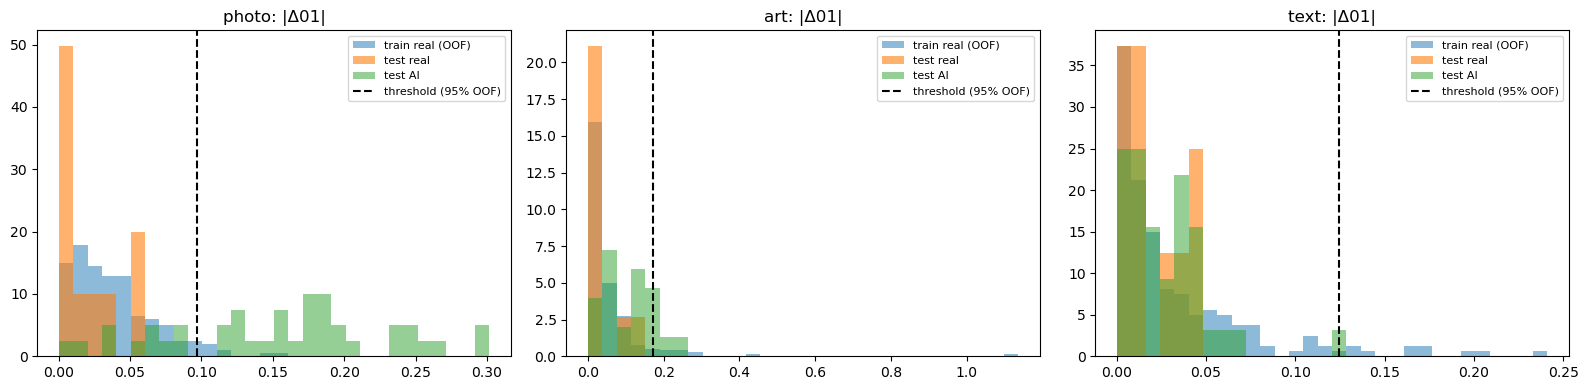

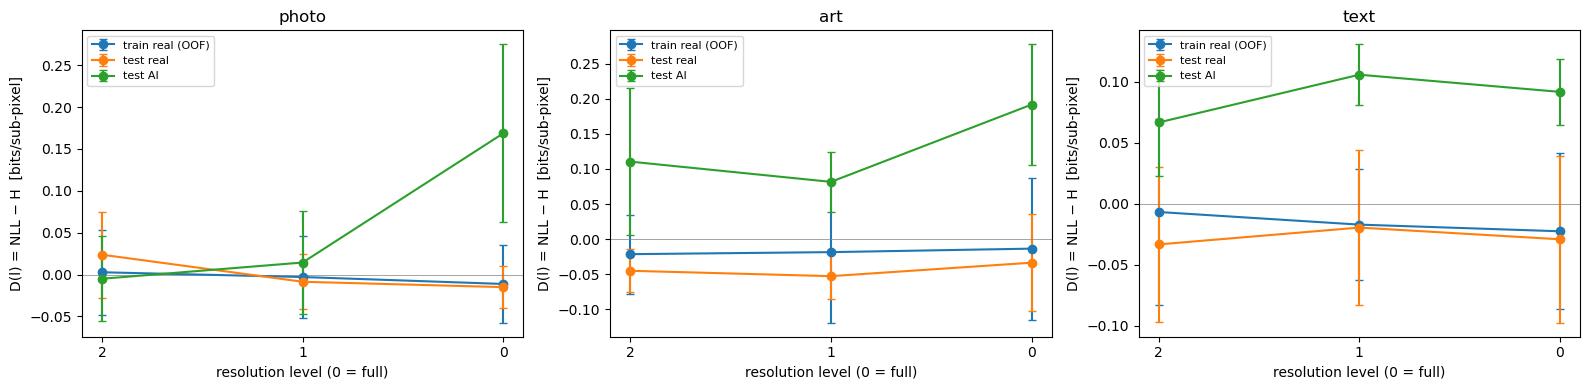

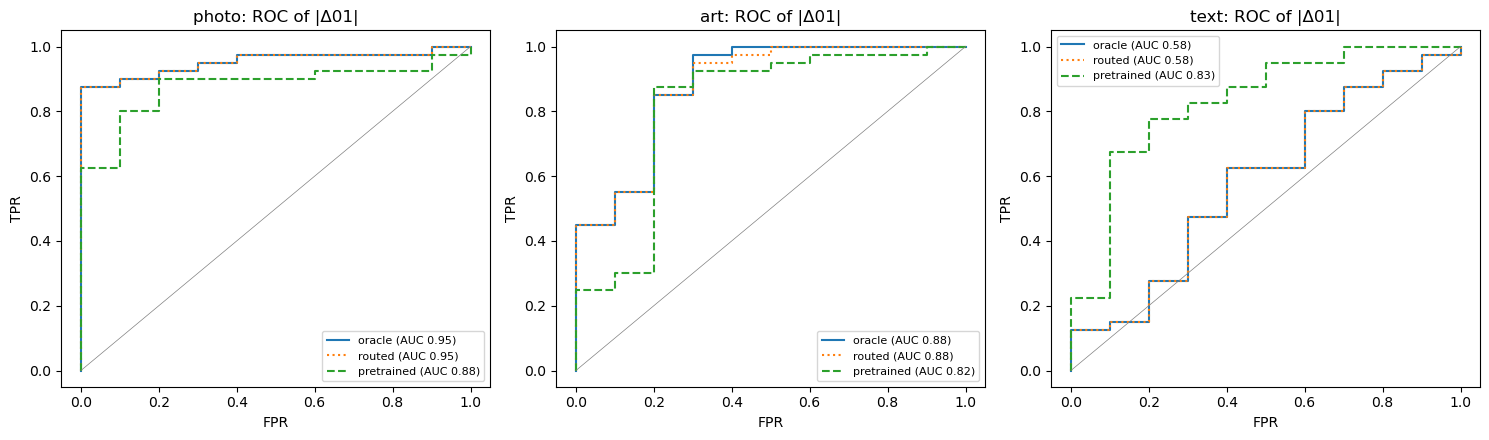

In [18]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, CATS):
    d = feat_df[(feat_df.route == "oracle") & (feat_df.true_cat == c)]
    bins = np.histogram_bin_edges(np.r_[oof_scores[c].absdelta01, d.absdelta01], 30)
    ax.hist(oof_scores[c].absdelta01, bins=bins, alpha=.5, label="train real (OOF)", density=True)
    ax.hist(d[d.label == 0].absdelta01, bins=bins, alpha=.6, label="test real", density=True)
    ax.hist(d[d.label == 1].absdelta01, bins=bins, alpha=.5, label="test AI", density=True)
    ax.axvline(thresholds[c]["absdelta01"], color="k", ls="--", label="threshold (95% OOF)")
    ax.set_title(f"{c}: |Δ01|"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "hist_absdelta01.png", dpi=120); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, CATS):
    d = feat_df[(feat_df.route == "oracle") & (feat_df.true_cat == c)]
    groups = [("train real (OOF)", oof_scores[c])] + [(n, d[d.label == l]) for l, n in [(0, "test real"), (1, "test AI")]]
    for name, dd in groups:
        m = [dd[f"D{l}"].mean() for l in (2, 1, 0)]; s = [dd[f"D{l}"].std() for l in (2, 1, 0)]
        ax.errorbar([2, 1, 0], m, yerr=s, marker="o", capsize=3, label=name)
    ax.axhline(0, color="grey", lw=.5); ax.set_xticks([2, 1, 0]); ax.invert_xaxis()
    ax.set_xlabel("resolution level (0 = full)"); ax.set_ylabel("D(l) = NLL − H  [bits/sub-pixel]"); ax.set_title(c); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "coding_cost_gap_levels.png", dpi=120); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, c in zip(axes, CATS):
    for route, ls in [("oracle", "-"), ("routed", ":"), ("pretrained", "--")]:
        d = feat_df[(feat_df.route == route) & (feat_df.true_cat == c)]
        if d.empty or d.label.nunique() < 2: continue
        fpr, tpr, _ = roc_curve(d.label, d.absdelta01)
        ax.plot(fpr, tpr, ls, label=f"{route} (AUC {roc_auc_score(d.label, d.absdelta01):.2f})")
    ax.plot([0, 1], [0, 1], color="grey", lw=.5); ax.set_title(f"{c}: ROC of |Δ01|")
    ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "roc_absdelta01.png", dpi=120); plt.show()

## 6. JPEG robustness check

ZED's model of "real" is whatever SReC was trained on. If re-saving a real image as JPEG moves its score past the threshold,
part of the detector is measuring the *file format* rather than AI generation. `flagged` is the fraction of these reals that would be called AI.

In [19]:
def jpeg_roundtrip(path, q):
    img = to_rgb(Image.open(path)); buf = io.BytesIO(); img.save(buf, "JPEG", quality=q); buf.seek(0)
    return prep_image(Image.open(buf))

rows = []
for c in CATS:
    for p in list_images(DATA / f"test/{c}/real")[:5]:
        for q in [None, 95, 90, 75]:
            x = (load_image_tensor(p) if q is None else jpeg_roundtrip(p, q)).to(DEVICE)
            f = zed_features(zed_levels(stream_models[c], x)); f.update(cat=c, path=str(p), jpeg_q=str(q or "PNG")); rows.append(f)
jd = pd.DataFrame(rows)
jd["flagged"] = jd.absdelta01 > jd.cat.map(lambda k: thresholds[k]["absdelta01"])
print(jd.groupby(["cat", "jpeg_q"], sort=False)[["D0", "delta01", "absdelta01", "flagged"]].mean().round(4))
print("\nthreshold |Δ01| per stream:", {c: round(thresholds[c]["absdelta01"], 4) for c in CATS})
jd.to_csv(OUT / "jpeg_robustness.csv", index=False)

                  D0  delta01  absdelta01  flagged
cat   jpeg_q                                      
photo PNG    -0.0208   0.0002      0.0220      0.0
      95     -0.0211  -0.0004      0.0457      0.2
      90     -0.0019   0.0259      0.0326      0.0
      75     -0.0104  -0.0150      0.0248      0.0
art   PNG    -0.0608  -0.0095      0.0163      0.0
      95      0.0702  -0.0336      0.0559      0.0
      90      0.0842  -0.0151      0.0449      0.0
      75      0.0721  -0.0598      0.0897      0.2
text  PNG    -0.0427  -0.0175      0.0175      0.0
      95      0.1331   0.0129      0.0467      0.0
      90      0.1415  -0.0001      0.0378      0.0
      75      0.1242  -0.0119      0.0452      0.0

threshold |Δ01| per stream: {'photo': 0.0971, 'art': 0.1721, 'text': 0.1242}


In [20]:
summary = dict(config=dict(N_TRAIN_PER_CAT=N_TRAIN_PER_CAT, N_TEST_FAKE=N_TEST_FAKE, N_TEST_REAL=N_TEST_REAL, K_FOLDS=K_FOLDS,
                           CROP=CROP, STEPS=STEPS, LR=LR, BATCH=BATCH, TRAIN_CROP=TRAIN_CROP, JPEG_AUG=JPEG_AUG,
                           TARGET_FPR=TARGET_FPR, PHOTO_FAKE_SOURCE=PHOTO_FAKE_SOURCE, TEXTRICH_CATS=TEXTRICH_CATS, SEED=SEED),
               category_cnn_oof_acc=float((oof_cat == train_labels).mean()),
               routing_acc_test=float((test_df.pred_cat == test_df.true_cat).mean()),
               headline_absdelta01={k: v[v.stat == "absdelta01"].set_index("cat")[["AUC", "bal_acc", "TPR", "FPR"]].round(4).to_dict("index")
                                    for k, v in results.items()})
json.dump(summary, open(OUT / "summary.json", "w"), indent=2)
print(json.dumps(summary, indent=2))

{
  "config": {
    "N_TRAIN_PER_CAT": 200,
    "N_TEST_FAKE": 40,
    "N_TEST_REAL": 10,
    "K_FOLDS": 5,
    "CROP": 512,
    "STEPS": 600,
    "LR": 3e-06,
    "BATCH": 8,
    "TRAIN_CROP": 128,
    "JPEG_AUG": 0.0,
    "TARGET_FPR": 0.05,
    "PHOTO_FAKE_SOURCE": "synthbuster",
    "TEXTRICH_CATS": [
      "AcademicPosters"
    ],
    "SEED": 0
  },
  "category_cnn_oof_acc": 0.9433333333333334,
  "routing_acc_test": 0.98,
  "headline_absdelta01": {
    "routed": {
      "photo": {
        "AUC": 0.9525,
        "bal_acc": 0.875,
        "TPR": 0.75,
        "FPR": 0.0
      },
      "art": {
        "AUC": 0.835,
        "bal_acc": 0.6125,
        "TPR": 0.225,
        "FPR": 0.0
      },
      "text": {
        "AUC": 0.585,
        "bal_acc": 0.5125,
        "TPR": 0.025,
        "FPR": 0.0
      },
      "ALL": {
        "AUC": 0.7211,
        "bal_acc": 0.6667,
        "TPR": 0.3333,
        "FPR": 0.0
      }
    },
    "oracle": {
      "photo": {
        "AUC": 0.9525,
    

## Notes

* **Surprise-score fidelity.** `NLL` is SReC's own training loss (`DiscretizedMixLogisticLoss`), checked against SReC's bit count in §3b.
  `H` is the exact entropy of the same discretized mixture. SReC's arithmetic coder truncates each distribution to the range allowed by
  the 2×2 block average. Like SReC's training loss, we use the untruncated distribution for both NLL and H, so the two are consistent.
* **No encode/decode needed.** Lossless decoding returns identical pixels, so one forward pass gives every distribution.
* **Crop, never resize.** The paper scores whole images. We use a 512×512 centre crop for speed and to make all images the same size, which
  removes size as a shortcut. Set `CROP = None` to score whole images, which is slower and lets sizes differ.
* **K-fold on real-only data** checks that fine-tuning lowers bpsp on unseen reals (`cv_log.csv`), and it gives a clean distribution of
  real scores for the threshold. The method stays zero-shot.
* **Remaining risks:**
  - The text stream is a domain shift (website screenshots for training, academic posters for testing). Compare `AUC` with `AUC_vs_OOFreal` and the test-real FPR.
  - AniPrO reals may be PNGs re-saved from JPEG; check `frac_jpeg_like` in the audit.
  - Danbooru PNGs can still be screenshots or edits.
  - 10 test reals per category give very coarse FPR estimates; rely on the CIs.